# WeLoveReviews: análisis de sentimiento en reseñas de clientes

## 1. Objetivos

Determinar la distribución positiva, neutral y negativa de las **500 reseñas esperadas**, contrastarla con el promedio declarado de **4.5/5** y evaluar posibles errores antes de comunicar conclusiones. La media de estrellas y la proporción de reseñas positivas son medidas distintas: **4.5/5 no equivale a 90% de positivas**.

Este documento usa exclusivamente `data/raw/reviews.csv`. Conserva todas las filas y los textos originales. Si faltan datos o ejecución, muestra el impedimento, no resultados sustitutos. La revisión cualitativa asistida por IA queda pendiente de validación humana.

In [1]:
import os
import sys
from pathlib import Path
import importlib.metadata as metadata

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

starting_path = Path(os.environ.get('WLR_ROOT', Path.cwd())).resolve()
ROOT = next((candidate for candidate in [starting_path, *starting_path.parents]
             if (candidate / 'src/app.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('No se encuentra el repositorio. Define WLR_ROOT con su ruta absoluta.')
sys.path.insert(0, str(ROOT / 'src'))
from app import (INPUT, OUTPUT, MODEL_ID, MODEL_REVISION, BANDS, SUPPORTED_LANGUAGES,
                 read_reviews, prepare_reviews, load_classifier, infer_reviews,
                 sentiment_summary, validate_results, verify_saved_csv, select_review_sample)

TEXT_COLUMN = None
RATING_COLUMN = None
ID_COLUMN = None
SEPARATOR = ','
ENCODING = 'utf-8-sig'
BATCH_SIZE = 8
DEVICE = 'cpu'
SEED = 42
AVAILABLE = INPUT.is_file()
original = prepared = result = None
audit = None

plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
display(pd.DataFrame({'paquete': ['pandas', 'torch', 'transformers', 'langdetect', 'nbconvert'],
                      'version': [metadata.version(name) for name in
                                  ['pandas', 'torch', 'transformers', 'langdetect', 'nbconvert']]}))
display(Markdown(f'**Modelo:** `{MODEL_ID}`. **Revisión fija:** `{MODEL_REVISION}`.'))
display(Markdown(f'**Estado:** {"CSV disponible" if AVAILABLE else "BLOQUEADO: falta data/raw/reviews.csv"}. '
                 'Se analiza únicamente el archivo aportado, sin datos sustitutos.'))

,paquete,version
0,pandas,2.3.3
1,torch,2.8.0+cpu
2,transformers,4.57.1
3,langdetect,1.0.9
4,nbconvert,7.16.6


**Modelo:** `nlptown/bert-base-multilingual-uncased-sentiment`. **Revisión fija:** `8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d`.

**Estado:** CSV disponible. Se analiza únicamente el archivo aportado, sin datos sustitutos.

## 2. EDA e insights

La auditoría identifica columnas reales sin asumir un esquema. Si hay ambigüedad, configura `TEXT_COLUMN`, `RATING_COLUMN` e `ID_COLUMN` en la celda inicial. Ajusta también separador y codificación si la exportación lo exige.

Se cuentan registros, nulos representados por campos vacíos del CSV, vacíos tras limpieza y duplicados adicionales de filas, texto e identificadores. **No se eliminan duplicados.** Los IDs se leen como texto para conservar ceros iniciales; cadenas como `NA` no se convierten automáticamente en nulos. La detección de idioma es una estimación reproducible, poco fiable en textos cortos: estos se marcan como indeterminados.

,columna,tipo_lectura,campos_vacios
0,review_id,object,0
1,rating,object,0
2,review_text,object,0


,auditoria
filas,500
utilizables,500
no_utilizables,0
diferencia_frente_a_500,0
columna_texto,review_text
columna_rating,rating
columna_id,review_id
nulos_texto,0
vacios_texto,0
duplicados_filas_adicionales,0


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great ...
1,2,5,Tried Harbor House Café after seeing it recomm...
2,3,5,Tried Harbor House Café after seeing it recomm...
3,4,5,Visited Harbor House Café last weekend. The st...
4,5,5,Grabbed a quick coffee at Harbor House Café th...


,caracteres,palabras
count,500.0,500.0
mean,170.2,29.1
std,27.1,4.8
min,86.0,14.0
25%,155.0,26.0
50%,173.0,29.0
75%,189.0,32.0
max,230.0,42.0


,reseñas
wl_idioma,
en,500


,review_id,rating,review_text
40,41,5,Grabbed a quick coffee at Harbor House Café th...
50,51,4,Grabbed a quick coffee at Harbor House Café th...
64,65,5,Tried Harbor House Café after seeing it recomm...
107,108,5,Grabbed a quick coffee at Harbor House Café th...
109,110,3,Regular customer at Harbor House Café here. Av...
112,113,4,Grabbed a quick coffee at Harbor House Café th...
176,177,2,Grabbed a quick coffee at Harbor House Café th...
194,195,2,Grabbed a quick coffee at Harbor House Café th...
291,292,5,Grabbed a quick coffee at Harbor House Café th...
312,313,3,Tried Harbor House Café after seeing it recomm...


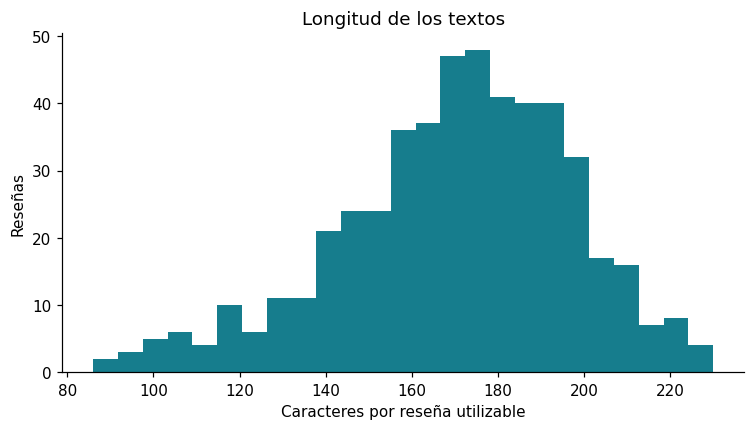

**Hallazgos de auditoría:** 500 filas; 500 utilizables; 0 no utilizables; 7 duplicados de texto adicionales. Diferencia frente a 500 utilizables: +0. 0 textos con idioma estimado fuera de los seis soportados. No se excluyen automáticamente; requieren cautela.

In [2]:
if AVAILABLE:
    original = read_reviews(INPUT, SEPARATOR, ENCODING)
    prepared, audit = prepare_reviews(original, TEXT_COLUMN, RATING_COLUMN, ID_COLUMN)
    display(pd.DataFrame({'columna': original.columns, 'tipo_lectura': original.dtypes.astype(str).values,
                          'campos_vacios': [original[column].eq('').sum() for column in original.columns]}))
    display(pd.Series({key: value for key, value in audit.items() if key != 'idiomas_estimados'}, name='auditoria').to_frame())
    display(original.head())
    lengths = pd.DataFrame({'caracteres': prepared.wl_texto_limpio.str.len(),
                            'palabras': prepared.wl_texto_limpio.str.split().str.len()})
    display(lengths.loc[prepared.wl_utilizable].describe().round(1))
    display(prepared.loc[prepared.wl_utilizable, 'wl_idioma'].value_counts().rename('reseñas').to_frame())
    duplicate_mask = original.duplicated(keep=False) | original[audit['columna_texto']].duplicated(keep=False)
    display(original.loc[duplicate_mask].head(10))
    if prepared.wl_utilizable.any():
        lengths.loc[prepared.wl_utilizable, 'caracteres'].plot.hist(bins=25, color='#167d8d')
        plt.xlabel('Caracteres por reseña utilizable'); plt.ylabel('Reseñas'); plt.title('Longitud de los textos'); plt.show()
    unsupported = prepared.wl_utilizable & ~prepared.wl_idioma.isin(SUPPORTED_LANGUAGES | {'indeterminado'})
    display(Markdown(f"**Hallazgos de auditoría:** {audit['filas']} filas; {audit['utilizables']} utilizables; "
                     f"{audit['no_utilizables']} no utilizables; {audit['duplicados_texto_adicionales']} duplicados de texto adicionales. "
                     f"Diferencia frente a 500 utilizables: {audit['diferencia_frente_a_500']:+d}. "
                     f"{int(unsupported.sum())} textos con idioma estimado fuera de los seis soportados. "
                     'No se excluyen automáticamente; requieren cautela.'))
else:
    display(Markdown('**EDA bloqueada:** coloca el archivo de la plataforma en `data/raw/reviews.csv`. No se conoce el esquema ni el número de reseñas utilizables.'))

## 3. Limpieza

Se conserva cada columna original. `wl_texto_limpio` únicamente recorta los extremos y normaliza espacios consecutivos; **no elimina negaciones, puntuación, acentos, emojis ni palabras**. Se conserva el orden con `wl_fila` (posición desde cero). Los duplicados siguen contando como filas de la exportación; no se interpreta ese conteo como clientes únicos.

Las filas con texto ausente, vacío o no textual permanecen en el CSV, con `wl_utilizable=False`, motivo documentado y predicciones vacías. El denominador de sentimiento incluye solo las utilizables. Los ratings humanos solo se aceptan como estrellas si son valores enteros entre 1 y 5; otros valores se señalan, no se transforman a una escala supuesta.

In [3]:
if prepared is not None:
    display(prepared[[audit['columna_texto'], 'wl_fila', 'wl_texto_limpio', 'wl_utilizable', 'wl_motivo']].head(10))
    display(Markdown(f"Textos modificados por normalización de espacios: "
                     f"{int(prepared[audit['columna_texto']].ne(prepared.wl_texto_limpio).sum())}. "
                     'No se eliminaron filas ni negaciones.'))
else:
    display(Markdown('Limpieza pendiente: no se dispone de textos reales.'))

,review_text,wl_fila,wl_texto_limpio,wl_utilizable,wl_motivo
0,Visited Harbor House Café last weekend. Great ...,0,Visited Harbor House Café last weekend. Great ...,True,
1,Tried Harbor House Café after seeing it recomm...,1,Tried Harbor House Café after seeing it recomm...,True,
2,Tried Harbor House Café after seeing it recomm...,2,Tried Harbor House Café after seeing it recomm...,True,
3,Visited Harbor House Café last weekend. The st...,3,Visited Harbor House Café last weekend. The st...,True,
4,Grabbed a quick coffee at Harbor House Café th...,4,Grabbed a quick coffee at Harbor House Café th...,True,
5,Stopped by Harbor House Café for the first tim...,5,Stopped by Harbor House Café for the first tim...,True,
6,Stopped by Harbor House Café for the first tim...,6,Stopped by Harbor House Café for the first tim...,True,
7,Came to Harbor House Café for a birthday brunc...,7,Came to Harbor House Café for a birthday brunc...,True,
8,Regular customer at Harbor House Café here. Av...,8,Regular customer at Harbor House Café here. Av...,True,
9,The pastries were incredible. The staff seemed...,9,The pastries were incredible. The staff seemed...,True,


Textos modificados por normalización de espacios: 0. No se eliminaron filas ni negaciones.

## 4. Plan y justificación del modelo

Se usa primero **nlptown/bert-base-multilingual-uncased-sentiment**, sin entrenamiento ni fine-tuning. La revisión inmutable verificada en Hugging Face es `8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d`, tanto para tokenizer como para modelo. Fuentes: [API del modelo](https://huggingface.co/api/models/nlptown/bert-base-multilingual-uncased-sentiment), [configuración fijada](https://huggingface.co/nlptown/bert-base-multilingual-uncased-sentiment/blob/8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d/config.json) y [ficha fijada](https://huggingface.co/nlptown/bert-base-multilingual-uncased-sentiment/blob/8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d/README.md).

El modelo fue ajustado con reseñas de **productos** en inglés, neerlandés, alemán, francés, italiano y español. Ese origen permite plantear un posible desajuste con servicios, pero no demuestra la causa de los errores. Sus métricas publicadas no miden la calidad en este negocio.

**Mapeo obligatorio:** 1–2 estrellas = negativo; 3 = neutral; 4–5 = positivo. El score es la probabilidad asignada a la etiqueta elegida: **no prueba corrección ni calibración**. Una sola carga por ejecución; lotes de 8 en CPU, configurables. Los pesos permanecen en la caché habitual de Hugging Face, no en el repositorio.

El modelo admite **512 tokens incluyendo especiales**. Se comprueba el límite del tokenizer y de la configuración al cargar. Se cuentan los tokens originales antes de truncar por la derecha; se guarda `wl_truncada`. Truncar puede perder la conclusión o una negación al final. No se aplican ventanas ni agregaciones no validadas en esta primera ejecución.

## 5. Inferencia

Se reutilizan las funciones de `app.py`, sin una segunda implementación. Primero ejecuta el script para producir el CSV; el notebook comprueba que coincide con sus resultados. Si no existe aún, lo genera con sus propias predicciones reales.

In [4]:
if prepared is not None and prepared.wl_utilizable.any():
    classifier, tokenizer, token_limit = load_classifier(DEVICE)
    result = infer_reviews(prepared, classifier, tokenizer, token_limit, BATCH_SIZE)
    validate_results(original, result)
    if OUTPUT.exists():
        verify_saved_csv(result, OUTPUT)
        csv_status = 'CSV existente coincide con la ejecución del notebook.'
    else:
        OUTPUT.parent.mkdir(parents=True, exist_ok=True)
        result.to_csv(OUTPUT, index=False)
        verify_saved_csv(result, OUTPUT)
        csv_status = 'CSV generado con predicciones reales y verificado.'
    display(Markdown(f'**Inferencia verificada:** {int(result.wl_utilizable.sum())} predicciones; '
                     f'{int(result.wl_truncada.sum())} textos truncados a {token_limit} tokens. {csv_status}'))
    display(result[['wl_fila', 'wl_estrellas', 'wl_sentimiento', 'wl_score', 'wl_tokens', 'wl_truncada']].head())
    display(result.loc[result.wl_utilizable, 'wl_tokens'].describe().to_frame())
else:
    display(Markdown('**Inferencia no ejecutada:** faltan datos o no hay textos utilizables. No se descargaron pesos ni se generó un CSV de predicciones.'))

Device set to use cpu


**Inferencia verificada:** 500 predicciones; 0 textos truncados a 512 tokens. CSV existente coincide con la ejecución del notebook.

,wl_fila,wl_estrellas,wl_sentimiento,wl_score,wl_tokens,wl_truncada
0,0,5,positivo,0.716958,40,False
1,1,5,positivo,0.98222,47,False
2,2,5,positivo,0.662324,43,False
3,3,5,positivo,0.989547,38,False
4,4,5,positivo,0.982912,41,False


,wl_tokens
count,500.0
mean,40.656
std,6.199559
min,20.0
25%,37.0
50%,41.0
75%,44.25
max,59.0


## 6. Resultados

Los conteos incluyen siempre negativo, neutral y positivo, incluso con cero casos. Los porcentajes usan reseñas utilizables y deben sumar 100% antes del redondeo. Se compara la media predicha con 4.5, pero esta media declarada es una **referencia externa**, cuya población y periodo no se conocen.

Si hay estrellas humanas válidas, se comparan humano y modelo únicamente sobre las mismas filas con ambas puntuaciones. Las diferencias describen desacuerdo, no prueban errores del modelo: una estrella humana puede reflejar aspectos que el texto no expresa. Sin estrellas humanas no se calcula exactitud ni se anuncian falsos negativos confirmados.

,conteo,porcentaje
sentimiento,,
negativo,47,9.4
neutral,41,8.2
positivo,412,82.4


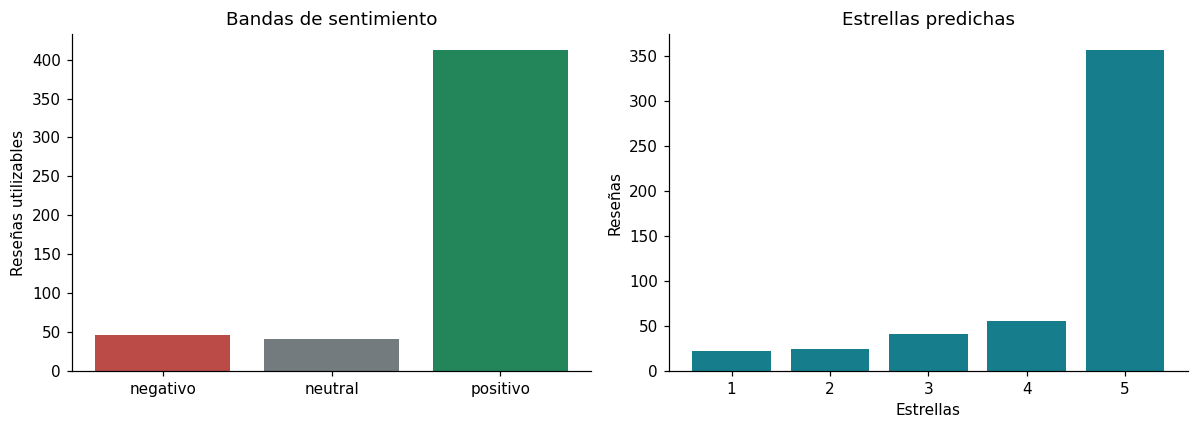

,medida,valor
0,Media predicha,4.398
1,Media declarada externa,4.500
2,Diferencia predicha - declarada,-0.102


,filas_comparadas,media_humana_mismas_filas,media_predicha_mismas_filas,desacuerdo_exacto,error_absoluto_medio_frente_a_rating
0,500,4.5,4.398,0.142,0.23


predicha,1,2,3,4,5
humana,,,,,
1,3,9,0,0,0
2,7,9,2,0,0
3,0,3,35,0,0
4,1,0,3,47,21
5,11,4,1,9,335


**Candidatos a falsos negativos por discrepancia:** 16. Es necesario leer el contenido antes de calificarlos como errores.

,review_text,wl_estrellas_humanas,wl_estrellas,wl_score
13,Tried Harbor House Café after seeing it recomm...,4.0,1,0.444348
14,Every dish was bursting with flavor. The place...,5.0,1,0.389345
72,Stopped by Harbor House Café for the first tim...,5.0,1,0.267875
86,Tried Harbor House Café after seeing it recomm...,5.0,1,0.324705
137,Tried Harbor House Café after seeing it recomm...,5.0,2,0.275117
199,Stopped by Harbor House Café for the first tim...,5.0,2,0.36852
203,Came to Harbor House Café for a birthday brunc...,5.0,1,0.349168
253,Stopped by Harbor House Café for the first tim...,5.0,1,0.364092
269,Stopped by Harbor House Café for the first tim...,5.0,1,0.409078
321,Every dish was bursting with flavor. The staff...,5.0,1,0.607708


In [5]:
if result is not None:
    summary = sentiment_summary(result)
    assert abs(summary.porcentaje.sum() - 100) < 1e-8
    display(summary.round({'porcentaje': 2}))
    star_counts = result.wl_estrellas.value_counts().reindex(range(1, 6), fill_value=0).sort_index()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].bar(summary.index, summary.conteo, color=['#bb4b47', '#747b7e', '#22865a'])
    axes[0].set(title='Bandas de sentimiento', ylabel='Reseñas utilizables')
    axes[1].bar(star_counts.index, star_counts.values, color='#167d8d')
    axes[1].set(title='Estrellas predichas', xlabel='Estrellas', ylabel='Reseñas', xticks=range(1, 6))
    plt.tight_layout(); plt.show()
    predicted_mean = float(result.wl_estrellas.mean())
    display(pd.DataFrame({'medida': ['Media predicha', 'Media declarada externa', 'Diferencia predicha - declarada'],
                          'valor': [predicted_mean, 4.5, predicted_mean - 4.5]}).round(3))
    paired = result.loc[result.wl_utilizable & result.wl_estrellas_humanas.notna()].copy()
    if len(paired):
        display(pd.DataFrame({'filas_comparadas': [len(paired)],
                              'media_humana_mismas_filas': [paired.wl_estrellas_humanas.mean()],
                              'media_predicha_mismas_filas': [paired.wl_estrellas.mean()],
                              'desacuerdo_exacto': [paired.wl_estrellas.ne(paired.wl_estrellas_humanas).mean()],
                              'error_absoluto_medio_frente_a_rating': [(paired.wl_estrellas - paired.wl_estrellas_humanas).abs().mean()]}).round(3))
        contingency = pd.crosstab(paired.wl_estrellas_humanas.astype(int), paired.wl_estrellas.astype(int))
        display(contingency.reindex(index=range(1, 6), columns=range(1, 6), fill_value=0).rename_axis(index='humana', columns='predicha'))
        candidates = paired.loc[paired.wl_estrellas.le(2) & paired.wl_estrellas_humanas.ge(4)]
        display(Markdown(f'**Candidatos a falsos negativos por discrepancia:** {len(candidates)}. '
                         'Es necesario leer el contenido antes de calificarlos como errores.'))
        display(candidates[[audit['columna_texto'], 'wl_estrellas_humanas', 'wl_estrellas', 'wl_score']].head(10))
    else:
        display(Markdown('Sin puntuaciones humanas válidas comparables: 4.5 es solo una referencia externa. No puede medirse exactitud sobre este conjunto.'))
else:
    display(Markdown('**Resultados pendientes:** no hay conteos, porcentajes ni promedio predicho reales. No es posible contrastar el 4.5 declarado.'))

## 7. Revisión cualitativa

Se seleccionaron y leyeron **20 reseñas sin repetir**: 10 aleatorias (`seed=42`) y 10 focalizadas en negativos frente a ratings humanos 4–5, discrepancias y señales de dudas. La parte focalizada **no permite estimar la frecuencia poblacional de errores**.

La tabla contiene texto completo, estrellas humanas, predicción, criterio de selección, interpretación y posible error. **Las 20 interpretaciones fueron realizadas por el agente, con asistencia de IA, no por una persona.** Los campos de validación y comentario humano siguen pendientes. No se modificaron las predicciones a partir de esta lectura.

La lectura distingue elogios al **personal**, quejas por **espera** y opiniones sobre **ambiente**; analiza el alcance de **negaciones** y el balance de **opiniones mixtas**. Por ejemplo, "never disappoints" niega decepción, mientras que "food made up for it" compensa una queja previa. Las coincidencias léxicas de las tablas auxiliares solo localizan textos, no interpretan su sentimiento.

Hay candidatos negativos cuyo contenido parece claramente positivo, no solo un rating discrepante. Los elogios a adaptación de alergias o trato personalizado mal clasificados justifican investigar el desajuste entre productos y servicios; existen también aciertos en servicio, así que no se atribuyen automáticamente todos los fallos a dominio. Las interpretaciones se conservan con los textos leídos y deben revisarse si cambia la muestra.

In [6]:
review_table = None
if result is not None:
    sample = select_review_sample(result, size=20, seed=SEED)
    annotations = {
        361: ('Average service, no complaints.', 'Neutral: café aceptable y servicio medio; "no complaints" niega quejas.', 'Sin error aparente de banda; 3 coincide con texto y rating.', 'personal; negación'),
        73: ('Five stars without hesitation.', 'Positiva: ambiente acogedor, comida sabrosa y cinco estrellas explícitas.', 'Sin error aparente; 5 es coherente con el texto.', 'ambiente; comida'),
        374: ('Service was fast and friendly.', 'Positiva: rapidez, amabilidad, ambiente y deseo de volver.', 'Sin error aparente de banda; score 0.489 no implica que sea incorrecta.', 'personal; espera; ambiente'),
        155: ('but overall a solid experience.', 'Mixta con balance positivo: café elogiado, personal molesto, experiencia global sólida.', '4 parece razonable; no ignorar la queja sobre personal.', 'personal; opinión mixta'),
        104: ('The staff were warm and attentive.', 'Positiva: personal atento, música/decoración y buena relación calidad-precio.', 'Sin error aparente; 5 concuerda con elogios y preferencia futura.', 'personal; ambiente'),
        394: ('We waited 25 minutes just to get water', 'Mixta: comida deliciosa y espera de 25 minutos; cierre global positivo pero dubitativo.', '4 es plausible, no prueba satisfacción con la espera; lectura humana necesaria.', 'espera; opinión mixta'),
        377: ('Loved the natural light and the plants everywhere.', 'Positiva: luz, plantas, pan y voluntad de convertirlo en lugar habitual.', 'Sin error aparente; 5 coherente.', 'ambiente; comida'),
        124: ('The team clearly cares about the customers.', 'Positiva: equipo atento, lugar para trabajar/socializar y recomendación explícita.', 'Sin error aparente; 5 coherente.', 'personal; ambiente'),
        68: ('Will definitely be back!', 'Positiva: ambiente acogedor y comida deliciosa, repetirá la visita.', 'Sin error aparente; 5 coherente.', 'ambiente; comida'),
        450: ('The staff were polite but a bit slow.', 'Neutral/mixta: sándwiches medios, personal educado pero lento y posible segunda visita.', '3 es plausible; la lentitud no vuelve toda la reseña negativa.', 'personal; espera; opinión mixta'),
        72: ('Service was fast and friendly.', 'Claramente positiva: rapidez, amabilidad, sabor, valor y próxima visita.', 'Candidato fuerte a falso negativo textual: 1 contradice elogios, además del rating 5; validar.', 'personal; espera; elogio'),
        331: ('They went out of their way to accommodate my allergy.', 'Positiva: adaptación a alergia, café excelente y deseo de volver.', 'Candidato fuerte a falso negativo: 1; "allergy" es contexto del elogio, no una queja.', 'personal; alergia; contexto de servicio'),
        253: ('Will definitely be back!', 'Positiva: adaptación a alergia y buen espacio para trabajar o ver amigos.', 'Candidato fuerte a falso negativo: 1 frente a contenido favorable y rating 5.', 'personal; alergia; ambiente'),
        269: ('Our server remembered our names by the second visit.', 'Positiva: trato personalizado, comida sabrosa, buen valor y retorno.', 'Candidato fuerte a falso negativo: 1 pese a elogios sin queja explícita.', 'personal; contexto de servicio'),
        408: ('Every dish was bursting with flavor.', 'Positiva: comida sabrosa, servicio rápido/amable y próxima visita.', 'Candidato fuerte a falso negativo: 1; posible dificultad con expresión idiomática, no causa demostrada.', 'comida; personal; espera; expresión idiomática'),
        473: ('This is now my go-to spot.', 'Positiva: elogios a comida y servicio; se convierte en su lugar habitual.', 'Candidato fuerte a falso negativo: 1 contradice el cierre favorable.', 'comida; personal; espera'),
        199: ('The music and decor set the perfect mood.', 'Positiva: ambiente perfecto, comida sabrosa y futura visita.', 'Candidato fuerte a falso negativo: 2 pese a elogios explícitos; validar.', 'ambiente; comida'),
        86: ('The seasonal menu never disappoints.', 'Positiva: "never disappoints" niega decepción; adaptación a alergia y regreso.', 'Candidato fuerte a falso negativo: 1; negación y contexto de alergia pueden ser pistas de dificultad, no explicación causal.', 'negación; personal; alergia'),
        203: ('but honestly the food made up for it.', 'Mixta con balance favorable: cajero grosero, compensado por comida, y deseo de volver.', 'Posible falso negativo de banda: 1 sobrerrepresenta la queja respecto al cierre; no se deduce solo del rating 5.', 'personal; opinión mixta; comida'),
        321: ('The staff seemed annoyed to be there', 'Mixta favorable: personal molesto, pero comida compensatoria y retorno explícito.', 'Posible falso negativo: 1 omite balance final favorable; score 0.608 no garantiza corrección.', 'personal; opinión mixta; comida'),
    }
    for position in sample.index:
        row = sample.loc[position]
        annotation = annotations.get(int(row.wl_fila))
        if annotation is None or annotation[0] not in row[audit['columna_texto']]:
            raise ValueError('La muestra o el texto cambió: volver a leer las reseñas antes de aplicar anotaciones IA.')
        sample.loc[position, ['interpretacion_IA', 'posible_error_IA', 'patron_IA']] = annotation[1:]
    selected_columns = ['wl_fila'] + ([audit['columna_id']] if audit['columna_id'] else [])
    selected_columns += [audit['columna_texto'], 'wl_estrellas_humanas', 'wl_estrellas',
                         'wl_sentimiento', 'wl_score', 'motivo_seleccion',
                         'interpretacion_IA', 'posible_error_IA', 'patron_IA',
                         'validacion_humana', 'comentario_humano']
    review_table = sample[selected_columns].copy()
    display(HTML(review_table.to_html(index=False, escape=True).replace('<table ', '<table style="width:100%;overflow-wrap:anywhere;" ')))
    display(Markdown(f'**Muestra:** {len(review_table)} reseñas: 10 aleatorias y 10 focalizadas. '
                     'Textos leídos e interpretados por el agente, revisión **asistida por IA**, no humana. '
                     'Validación y comentario humano: pendientes. Los casos focalizados no estiman una tasa poblacional de error.'))
    topics = {
        'personal': r'\b(?:personal|camarer\w*|emplead\w*|staff|team|server|cashier|waiter\w*|service|servicio)\b',
        'espera': r'\b(?:esper\w*|cola|demora|lent\w*|wait\w*|queue|slow|fast)\b',
        'ambiente': r'\b(?:ambiente|ruido|música|musica|decor\w*|atmosphere|noise|music|cozy|vibe|light|plants)\b',
        'negaciones': r'\b(?:no|not|never|nunca|sin|neither|without)\b',
        'opiniones_mixtas_posibles': r'\b(?:pero|aunque|but|however|despite)\b',
    }
    topic_counts = []
    for topic, pattern in topics.items():
        matches = result.wl_utilizable & result.wl_texto_limpio.str.contains(pattern, case=False, regex=True)
        topic_counts.append({'señal_lexica': topic, 'textos': int(matches.sum()),
                             'predichos_negativos': int((matches & result.wl_estrellas.le(2)).sum())})
        examples = result.loc[matches, ['wl_fila', audit['columna_texto'], 'wl_estrellas_humanas', 'wl_estrellas']].head(3)
        display(Markdown(f'**Ejemplos de contexto: {topic}**'))
        display(examples)
    display(pd.DataFrame(topic_counts))
    display(Markdown('Los conteos son señales léxicas solapadas, no aspectos evaluados ni errores confirmados. '
                     'La tabla interpretada muestra elogios al servicio/alergias mal clasificados, negación positiva y opiniones mixtas. '
                     'No todos los errores potenciales son atribuibles a dominio.'))
else:
    display(Markdown('**Revisión cualitativa bloqueada:** no hay textos utilizables para leer.'))

wl_fila,review_id,review_text,wl_estrellas_humanas,wl_estrellas,wl_sentimiento,wl_score,motivo_seleccion,interpretacion_IA,posible_error_IA,patron_IA,validacion_humana,comentario_humano
361,362,"Stopped by Harbor House Café for the first time. The coffee was okay. Average service, no complaints. It's fine for a quick stop.",3.0,3,neutral,0.769721,aleatoria (semilla 42),"Neutral: café aceptable y servicio medio; ""no complaints"" niega quejas.",Sin error aparente de banda; 3 coincide con texto y rating.,personal; negación,pendiente,pendiente
73,74,"Stopped by Harbor House Café for the first time. The place has such a cozy, welcoming vibe. Every dish was bursting with flavor. Five stars without hesitation.",5.0,5,positivo,0.936192,aleatoria (semilla 42),"Positiva: ambiente acogedor, comida sabrosa y cinco estrellas explícitas.",Sin error aparente; 5 es coherente con el texto.,ambiente; comida,pendiente,pendiente
374,375,"Grabbed a quick coffee at Harbor House Café this morning. Service was fast and friendly. The place has such a cozy, welcoming vibe. Reasonably priced for the quality. Already planning my next visit.",5.0,5,positivo,0.488904,aleatoria (semilla 42),"Positiva: rapidez, amabilidad, ambiente y deseo de volver.",Sin error aparente de banda; score 0.489 no implica que sea incorrecta.,personal; espera; ambiente,pendiente,pendiente
155,156,"Grabbed a quick coffee at Harbor House Café this morning. The coffee was rich and perfectly brewed. The staff seemed annoyed to be there, but overall a solid experience. It's fine for a quick stop.",4.0,4,positivo,0.707307,aleatoria (semilla 42),"Mixta con balance positivo: café elogiado, personal molesto, experiencia global sólida.",4 parece razonable; no ignorar la queja sobre personal.,personal; opinión mixta,pendiente,pendiente
104,105,Grabbed a quick coffee at Harbor House Café this morning. The staff were warm and attentive. The music and decor set the perfect mood. Great value for what you get. This is now my go-to spot.,5.0,5,positivo,0.838429,aleatoria (semilla 42),"Positiva: personal atento, música/decoración y buena relación calidad-precio.",Sin error aparente; 5 concuerda con elogios y preferencia futura.,personal; ambiente,pendiente,pendiente
394,395,"The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. Might give it another shot.",4.0,4,positivo,0.703625,aleatoria (semilla 42),Mixta: comida deliciosa y espera de 25 minutos; cierre global positivo pero dubitativo.,"4 es plausible, no prueba satisfacción con la espera; lectura humana necesaria.",espera; opinión mixta,pendiente,pendiente
377,378,Visited Harbor House Café last weekend. Loved the natural light and the plants everywhere. The sourdough bread alone is worth the visit. Worth every penny. This is now my go-to spot.,5.0,5,positivo,0.750138,aleatoria (semilla 42),"Positiva: luz, plantas, pan y voluntad de convertirlo en lugar habitual.",Sin error aparente; 5 coherente.,ambiente; comida,pendiente,pendiente
124,125,Regular customer at Harbor House Café here. The team clearly cares about the customers. Great spot to work or catch up with friends. Worth every penny. Highly recommend to anyone in the area.,5.0,5,positivo,0.751169,aleatoria (semilla 42),"Positiva: equipo atento, lugar para trabajar/socializar y recomendación explícita.",Sin error aparente; 5 coherente.,personal; ambiente,pendiente,pendiente
68,69,"Visited Harbor House Café last weekend. The place has such a cozy, welcoming vibe. The food was absolutely delicious. Worth every penny. Will definitely be back!",5.0,5,positivo,0.82096,aleatoria (semilla 42),"Positiva: ambiente acogedor y comida deliciosa, repetirá la visita.",Sin error aparente; 5 coherente.,ambiente; comida,pendiente,pendiente
450,451,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. Might give it another shot.",3.0,3,neutral,0.65301,aleatoria (semilla 42),"N

**Muestra:** 20 reseñas: 10 aleatorias y 10 focalizadas. Textos leídos e interpretados por el agente, revisión **asistida por IA**, no humana. Validación y comentario humano: pendientes. Los casos focalizados no estiman una tasa poblacional de error.

**Ejemplos de contexto: personal**

,wl_fila,review_text,wl_estrellas_humanas,wl_estrellas
3,3,Visited Harbor House Café last weekend. The st...,5.0,5
6,6,Stopped by Harbor House Café for the first tim...,5.0,5
7,7,Came to Harbor House Café for a birthday brunc...,5.0,5


**Ejemplos de contexto: espera**

...

,wl_fila,review_text,wl_estrellas_humanas,wl_estrellas
1,1,Tried Harbor House Café after seeing it recomm...,5.0,5
2,2,Tried Harbor House Café after seeing it recomm...,5.0,5
3,3,Visited Harbor House Café last weekend. The st...,5.0,5


**Ejemplos de contexto: opiniones_mixtas_posibles**

,wl_fila,review_text,wl_estrellas_humanas,wl_estrellas
8,8,Regular customer at Harbor House Café here. Av...,3.0,3
9,9,The pastries were incredible. The staff seemed...,5.0,5
15,15,Stopped by Harbor House Café for the first tim...,3.0,3


,señal_lexica,textos,predichos_negativos
0,personal,319,27
1,espera,110,8
2,ambiente,170,3
3,negaciones,136,11
4,opiniones_mixtas_posibles,116,3


Los conteos son señales léxicas solapadas, no aspectos evaluados ni errores confirmados. La tabla interpretada muestra elogios al servicio/alergias mal clasificados, negación positiva y opiniones mixtas. No todos los errores potenciales son atribuibles a dominio.

## 8. Conclusiones para la account manager

**El contenido escrito es mayoritariamente positivo:** 412 de 500 reseñas (82.4%), con 41 neutrales (8.2%) y 47 negativas (9.4%). Las 500 filas son utilizables, todas tienen predicción y no se eliminó ninguna. Hay siete duplicados adicionales de texto, conservados; no hay IDs duplicados ni textos vacíos. Los 500 textos se detectan como inglés. Tienen entre 20 y 59 tokens, muy por debajo del límite 512: **el truncamiento no explica los desacuerdos de esta ejecución**.

La media predicha es **4.398/5**, 0.102 puntos menor que la referencia declarada **4.5/5**. Los ratings humanos de **estas mismas 500 filas** también promedian 4.5; esa coincidencia no verifica por sí sola la procedencia ni el periodo del promedio de la plataforma. Las distribuciones humanas son 12 reseñas de 1 estrella, 18 de 2, 38 de 3, 72 de 4 y 360 de 5; las predichas son 22, 25, 41, 56 y 356, respectivamente. La banda positiva humana representa **432/500 = 86.4%**, no 90%; el modelo estima cuatro puntos porcentuales menos. Hay **71 desacuerdos exactos (14.2%)** y **16 candidatos a falsos negativos** por rating humano 4–5 frente a predicción 1–2. Desacuerdo de estrellas no es sinónimo de error textual.

**La lectura asistida por IA encuentra posibles errores importantes:**

- ID 73 (`wl_fila=72`): "Service was fast and friendly" y "Already planning my next visit" son elogios claros, pero el modelo predice 1 estrella frente a rating 5; candidato fuerte a falso negativo textual.
- ID 87: "The seasonal menu never disappoints" y la adaptación a una alergia describen una experiencia favorable. El modelo predice 1 estrella. La negación de decepción y el contexto de servicio son pistas a investigar, no causas probadas.
- ID 322: el personal parecía molesto, "but honestly the food made up for it" y "Will definitely be back!" compensan la queja. El modelo asigna 1 estrella con score 0.608: la confianza no garantiza una interpretación correcta del balance mixto.
- ID 395: la comida era deliciosa, pero esperaron 25 minutos para recibir agua; el modelo y el rating asignan 4. La coincidencia no significa que no exista una fricción operativa.
- ID 362: "Average service, no complaints" expresa una valoración media, no una queja por la palabra "complaints". La predicción neutral resulta plausible.

El modelo procede de reseñas de productos, mientras que aquí debe ponderar trato personalizado, alergias, ambiente y espera. Los fallos en elogios al servicio, junto con aciertos en otras reseñas de servicio, respaldan **investigar** desajuste de dominio, negaciones, expresiones idiomáticas y balance mixto; no permiten atribuir todos los errores a una sola causa. Se necesitaría una evaluación textual validada y experimentos controlados para distinguirlas.

**Recomendación:** no comunicar el 9.4% negativo como porcentaje confirmado de clientes insatisfechos. Validar los 16 candidatos frente al texto y revisar menciones concretas de espera y trato al cliente incluso en reseñas globalmente positivas. Mantener las predicciones originales: no se han corregido automáticamente a partir de esta revisión.

El agente leyó **20 ejemplos: 10 aleatorios con semilla 42 y 10 focalizados**, y dejó interpretación, posible error y patrón en la tabla. Esta revisión es **asistida por IA, no una revisión humana**; todos los campos de validación/comentario humano permanecen pendientes. La muestra focalizada no estima la frecuencia de errores en el conjunto; se requiere validación humana antes de presentar hipótesis cualitativas como hallazgos confirmados.

In [7]:
if result is not None:
    summary = sentiment_summary(result)
    usable_count = int(result.wl_utilizable.sum())
    mean = float(result.wl_estrellas.mean())
    distribution = '; '.join(f'{band}: {int(summary.loc[band, "conteo"])} ({summary.loc[band, "porcentaje"]:.2f}%)'
                             for band in BANDS)
    display(Markdown(f'**Resumen cuantitativo:** de {len(result)} filas exportadas, '
                     f'{usable_count} son utilizables y {len(result) - usable_count} no tienen predicción. '
                     f'{distribution}. Media predicha: {mean:.3f}/5, diferencia de {mean - 4.5:+.3f} '
                     f'frente a 4.5/5. {int(result.wl_truncada.sum())} textos fueron truncados. '
                     'Las bandas del modelo no son una medición validada de satisfacción.'))
    if len(paired):
        from app import star_to_sentiment
        human_bands = paired.wl_estrellas_humanas.map(star_to_sentiment).value_counts().reindex(BANDS, fill_value=0)
        predicted_bands = paired.wl_sentimiento.value_counts().reindex(BANDS, fill_value=0)
        comparison = pd.DataFrame({'humana_conteo': human_bands, 'predicha_conteo': predicted_bands,
                                   'humana_porcentaje': human_bands / len(paired) * 100,
                                   'predicha_porcentaje': predicted_bands / len(paired) * 100})
        comparison['diferencia_puntos_porcentuales'] = comparison.predicha_porcentaje - comparison.humana_porcentaje
        display(comparison.round(2))
        display(Markdown(f'**Mismas filas ({len(paired)}):** media humana {paired.wl_estrellas_humanas.mean():.3f}, '
                         f'media predicha {paired.wl_estrellas.mean():.3f}. '
                         'El 4.5 declarado sigue siendo una referencia de procedencia/periodo no verificados.'))
    ia_completed = review_table is not None and review_table[['interpretacion_IA', 'posible_error_IA', 'patron_IA']].ne('pendiente').all().all()
    display(Markdown(f'**Revisión cualitativa:** {len(review_table) if review_table is not None else 0} textos '
                     f'{"leídos y anotados por el agente, con asistencia de IA" if ia_completed else "pendientes de lectura"}. '
                     'No se modificaron las predicciones. Todos los comentarios y validaciones humanas permanecen pendientes.'))
    verification = pd.DataFrame({'comprobacion': ['Conservación de filas y originales', 'Predicción en todas las utilizables',
                                                'Mapeo de cinco estrellas', 'Porcentajes ≈ 100%', 'Coincidencia con CSV',
                                                '500 utilizables', 'Revisión cualitativa asistida por IA', 'Validación humana'],
                                 'estado': ['verificado', 'verificado', 'verificado', 'verificado', 'verificado',
                                            'verificado' if usable_count == 500 else f'no: {usable_count} utilizables',
                                            'completada' if ia_completed else 'pendiente', 'pendiente']})
    display(verification)
else:
    display(Markdown('**Conclusión actual:** no hay datos utilizables para inferencia y revisión. No se inventan resultados.'))

**Resumen cuantitativo:** de 500 filas exportadas, 500 son utilizables y 0 no tienen predicción. negativo: 47 (9.40%); neutral: 41 (8.20%); positivo: 412 (82.40%). Media predicha: 4.398/5, diferencia de -0.102 frente a 4.5/5. 0 textos fueron truncados. Las bandas del modelo no son una medición validada de satisfacción.

,humana_conteo,predicha_conteo,humana_porcentaje,predicha_porcentaje,diferencia_puntos_porcentuales
negativo,30,47,6.0,9.4,3.4
neutral,38,41,7.6,8.2,0.6
positivo,432,412,86.4,82.4,-4.0


**Mismas filas (500):** media humana 4.500, media predicha 4.398. El 4.5 declarado sigue siendo una referencia de procedencia/periodo no verificados.

**Revisión cualitativa:** 20 textos leídos y anotados por el agente, con asistencia de IA. No se modificaron las predicciones. Todos los comentarios y validaciones humanas permanecen pendientes.

,comprobacion,estado
0,Conservación de filas y originales,verificado
1,Predicción en todas las utilizables,verificado
2,Mapeo de cinco estrellas,verificado
3,Porcentajes ≈ 100%,verificado
4,Coincidencia con CSV,verificado
5,500 utilizables,verificado
6,Revisión cualitativa asistida por IA,completada
7,Validación humana,pendiente
